# Red Wine Quality

## Câu 3. Tương quan Pearson

### Yêu cầu

Khảo sát tương quan Pearson, biểu diễn heatmap có giá trị và loại thuộc tính tương quan cao.

### Dữ liệu và phương pháp

Thuộc tính quyết định: quality. Sử dụng toàn bộ dữ liệu được cung cấp. Chia huấn luyện 70%, kiểm thử 30%, random_state=42 theo đề. Tương quan cao được quy ước là |r| ≥ 0,8 giữa các thuộc tính đầu vào; giữ cột đứng trước trong thứ tự gốc.

In [1]:
print("Đặng Ngọc Hiếu - 6451071024")

from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

ROOT = Path.cwd()
while not (ROOT / "datasets").is_dir():
    if (ROOT / "6451071024_Lab2" / "datasets").is_dir():
        ROOT = ROOT / "6451071024_Lab2"
        break
    if ROOT == ROOT.parent:
        raise FileNotFoundError("Không tìm thấy thư mục datasets của LAB2.")
    ROOT = ROOT.parent
pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid", font="DejaVu Sans")


raw = pd.read_csv(ROOT / "datasets/wine/winequality-red.csv")
TARGET = "quality"
if TARGET not in raw or raw.empty or raw.isna().any().any():
    raise ValueError("Kiểm tra dữ liệu Wine: cần có quality và không có ô trống.")
data = raw.copy()


Đặng Ngọc Hiếu - 6451071024


Đặng Ngọc Hiếu - 6451071024
Quy ước tương quan cao: |r| >= 0.8


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol
fixed acidity,1.000000,-0.256131,0.671703,0.114777,0.093705,-0.153794,-0.113181,0.668047,-0.682978,0.183006,-0.061668
volatile acidity,-0.256131,1.000000,-0.552496,0.001918,0.061298,-0.010504,0.076470,0.022026,0.234937,-0.260987,-0.202288
citric acid,0.671703,-0.552496,1.000000,0.143577,0.203823,-0.060978,0.035533,0.364947,-0.541904,0.312770,0.109903
residual sugar,0.114777,0.001918,0.143577,1.000000,0.055610,0.187049,0.203028,0.355283,-0.085652,0.005527,0.042075
chlorides,0.093705,0.061298,0.203823,0.055610,1.000000,0.005562,0.047400,0.200632,-0.265026,0.371260,-0.221141
free sulfur dioxide,-0.153794,-0.010504,-0.060978,0.187049,0.005562,1.000000,0.667666,-0.021946,0.070377,0.051658,-0.069408
total sulfur dioxide,-0.113181,0.076470,0.035533,0.203028,0.047400,0.667666,1.000000,0.071269,-0.066495,0.042947,-0.205654
density,0.668047,0.022026,0.364947,0.355283,0.200632,-0.021946,0.071269,1.000000,-0.341699,0.148506,-0.496180
pH,-0.682978,0.234937,-0.541904,-0.085652,-0.265026,0.070377,-0.066495,-0.341699,1.000000,-0.196648,0.205633
sulphates,0.183006,-0.260987,0.312770,0.005527,0.371260,0.051658,0.042947,0.148506,-0.196648,1.000000,0.093595


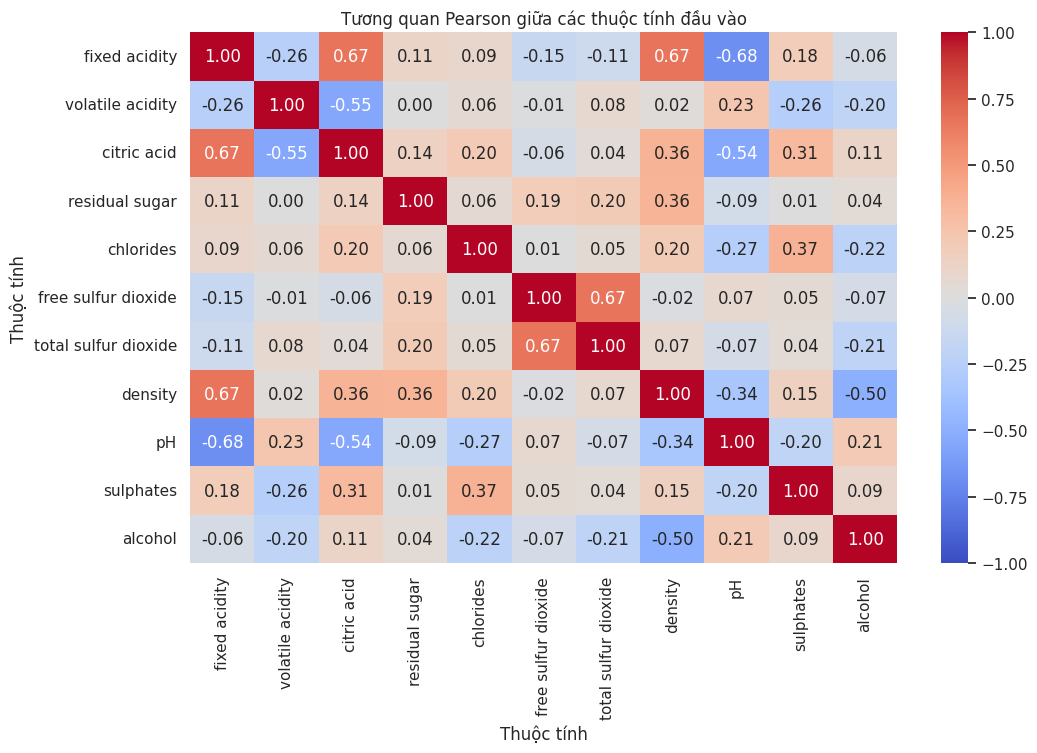

,Cột giữ,Cột loại,Pearson r


Các cột loại: Không có
Kích thước trước loại cột: (1599, 12)
Kích thước sau loại cột: (1599, 12)


In [2]:
print("Đặng Ngọc Hiếu - 6451071024")

# Pearson chỉ có ý nghĩa trực tiếp trên các cột số, không mã hóa nhãn để loại cột.
numeric = data.drop(columns=TARGET).select_dtypes(include="number")
CORRELATION_THRESHOLD = 0.8  # Quy ước triển khai; đề không ấn định ngưỡng số.
corr = numeric.corr(method="pearson")
print("Quy ước tương quan cao: |r| >=", CORRELATION_THRESHOLD)
display(corr)
plt.figure(figsize=(max(7, len(corr)), max(5, len(corr)*0.7)))
sns.heatmap(corr, annot=True, fmt=".2f", vmin=-1, vmax=1, cmap="coolwarm")
plt.title("Tương quan Pearson giữa các thuộc tính đầu vào")
plt.xlabel("Thuộc tính")
plt.ylabel("Thuộc tính")
plt.tight_layout()
plt.show()
plt.close()

# Xét theo thứ tự cột gốc; giữ cột trước, bỏ cột sau nếu tương quan cao với cột giữ.
drop_columns = []
pairs = []
for j, column in enumerate(corr.columns):
    for previous in corr.columns[:j]:
        value = corr.loc[previous, column]
        if previous not in drop_columns and pd.notna(value) and abs(value) >= CORRELATION_THRESHOLD:
            drop_columns.append(column)
            pairs.append({"Cột giữ": previous, "Cột loại": column, "Pearson r": value})
            break
display(pd.DataFrame(pairs, columns=["Cột giữ", "Cột loại", "Pearson r"]))
print("Các cột loại:", drop_columns if drop_columns else "Không có")
print("Kích thước trước loại cột:", data.shape)
data = data.drop(columns=drop_columns)
print("Kích thước sau loại cột:", data.shape)
